# Qismet: audit the QUBO before scaling

This executed notebook reads the diagnostic artifacts produced by `run_audit.py`.
It asks whether QAOA finds the surrogate optimum, whether pairwise interactions improve
prediction over a linear-only model, and whether either model selects useful subnetworks.

**Scope:** original three Two Moons initializations; 8 hidden neurons; retain 4;
128 fit masks and 35 held-out feasible masks per seed. All 70 feasible masks per seed
were retrained for 200 full-batch Adam steps, with validation metrics at every epoch.
Test data was not evaluated. This is exploratory reuse of the original audit split,
not a new confirmatory experiment.

To regenerate underlying measurements, run `python run_audit.py` in this folder using
the original Qismet environment. The script needs the sibling `results/` checkpoints
and `experiment_utils.py`; it does not modify them. Then rerun this notebook.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display, Markdown, Image
BASE=Path('.')
metrics=pd.read_csv(BASE/'surrogate_metrics.csv')
solver=pd.read_csv(BASE/'solver_comparison.csv',dtype={'qaoa_mask':str,'random_mask':str,'exact_qubo_mask':str})
selection=pd.read_csv(BASE/'selection_comparison.csv',dtype={'mask':str})
all_masks=pd.read_csv(BASE/'all_feasible_masks.csv',dtype={'mask':str})
curves=pd.read_csv(BASE/'validation_curves.csv')
assert len(all_masks)==210 and len(curves)==42000
assert all_masks.groupby('seed').size().eq(70).all()
assert metrics.n_audit.eq(35).all()
print('Verified: 210 masks, 42,000 validation checkpoints, 35 audit masks per initialization.')


Verified: 210 masks, 42,000 validation checkpoints, 35 audit masks per initialization.


## QAOA versus exact search and random masks

Mask strings are in neuron-index order: a 1 retains that neuron. Hamming distance counts
positions that differ. The surrogate gap is measured against the exact minimum over all
70 four-neuron masks. A gap above zero means the finite-shot QAOA selection missed the optimum.


In [2]:
display(solver.round(6))

,seed,qaoa_mask,random_mask,exact_qubo_mask,qaoa_equals_random,qaoa_random_hamming,qaoa_equals_exact,qaoa_surrogate_gap,qaoa_feasible_mass,qaoa_top10_given_feasible,uniform_top10_given_feasible
0,11,10111000,01010101,11101000,False,6,False,0.004643,0.608178,0.100322,0.1
1,22,10011001,01010101,10001011,False,4,False,0.009324,0.759991,0.100486,0.1
2,33,01010101,00101011,11010001,False,6,False,0.020972,0.748930,0.100987,0.1


## Linear-only versus pairwise surrogate

The linear model uses the same original fitting labels, ridge-alpha candidates, and CV splits
as the original quadratic model. The quadratic coefficients are reused unchanged. Higher
Spearman cost-versus-loss correlation is better; cost-versus-accuracy should be negative.
R² below zero means predictions are worse in squared error than the held-out mean.


In [3]:
display(metrics.round(4))
display(metrics.groupby('model')[['MAE','R2','Spearman_cost_vs_loss','Spearman_cost_vs_accuracy']].mean().round(4))

,seed,model,n_audit,MAE,R2,Spearman_cost_vs_loss,ridge_alpha,Spearman_cost_vs_accuracy
0,11,Linear only,35,0.0432,-0.3978,0.2658,1.0000,-0.3385
1,11,Quadratic,35,0.0320,-0.2622,0.2874,0.1000,-0.3135
2,22,Linear only,35,0.0392,0.1991,0.5588,1.0000,-0.1768
3,22,Quadratic,35,0.0362,0.2997,0.5246,1.0000,-0.1642
4,33,Linear only,35,0.0310,-0.0130,0.7059,1.0000,-0.5166
5,33,Quadratic,35,0.0287,-0.1224,0.4678,0.0001,-0.4565


,MAE,R2,Spearman_cost_vs_loss,Spearman_cost_vs_accuracy
model,,,,
Linear only,0.0378,-0.0706,0.5102,-0.3440
Quadratic,0.0323,-0.0283,0.4266,-0.3114


## Selecting masks and retraining

`all70` selection searches the entire feasible set. `audit35` compares surrogate selection
on masks whose retraining labels were excluded from fitting. Validation-loss regret is the
excess over the best actual validation loss in that same candidate set. The oracle is a
retrospective reference, not an independently validated winning network.


In [4]:
display(selection.round(5))
display(selection.groupby(['candidate_pool','method'])[['val_loss','val_accuracy','val_loss_regret']].mean().round(5))

,seed,method,state,mask,candidate_pool,val_loss,val_accuracy,val_loss_regret
0,11,QAOA,29,10111000,all70,0.15954,0.93333,0.00825
1,11,Random,170,01010101,all70,0.15803,0.93000,0.00674
2,11,Exact linear,29,10111000,all70,0.15954,0.93333,0.00825
3,11,Exact quadratic,23,11101000,all70,0.15665,0.93333,0.00536
4,11,Validation oracle (diagnostic),85,10101010,all70,0.15129,0.93333,0.00000
5,11,Audit-only linear,15,11110000,audit35,0.15797,0.93333,0.00668
6,11,Audit-only quadratic,149,10101001,audit35,0.15382,0.93333,0.00253
7,11,Audit-only oracle (diagnostic),85,10101010,audit35,0.15129,0.93333,0.00000
8,22,QAOA,153,10011001,all70,0.15637,0.93333,0.00391
9,22,Random,170,01010101,all70,0.15710,0.93000,0.00463


val_loss  val_accuracy  \
candidate_pool method                                                   
all70          Exact linear                     0.15470       0.93333   
               Exact quadratic                  0.15489       0.93556   
               QAOA                             0.15777       0.93556   
               Random                           0.15560       0.93333   
               Validation oracle (diagnostic)   0.15126       0.93556   
audit35        Audit-only linear                0.15551       0.93111   
               Audit-only oracle (diagnostic)   0.15166       0.93667   
               Audit-only quadratic             0.15394       0.93556   

                                               val_loss_regret  
candidate_pool method                                           
all70          Exact linear                            0.00344  
               Exact quadratic                         0.00362  
               QAOA                                    0.00650  
               Random                                  0.00434  
               Validation oracle (diagnostic)          0.00000  
audit35        Audit-only linear                       0.00385  
               Audit-only oracle (diagnostic)          0.00000  
               Audit-only quadratic                    0.00228

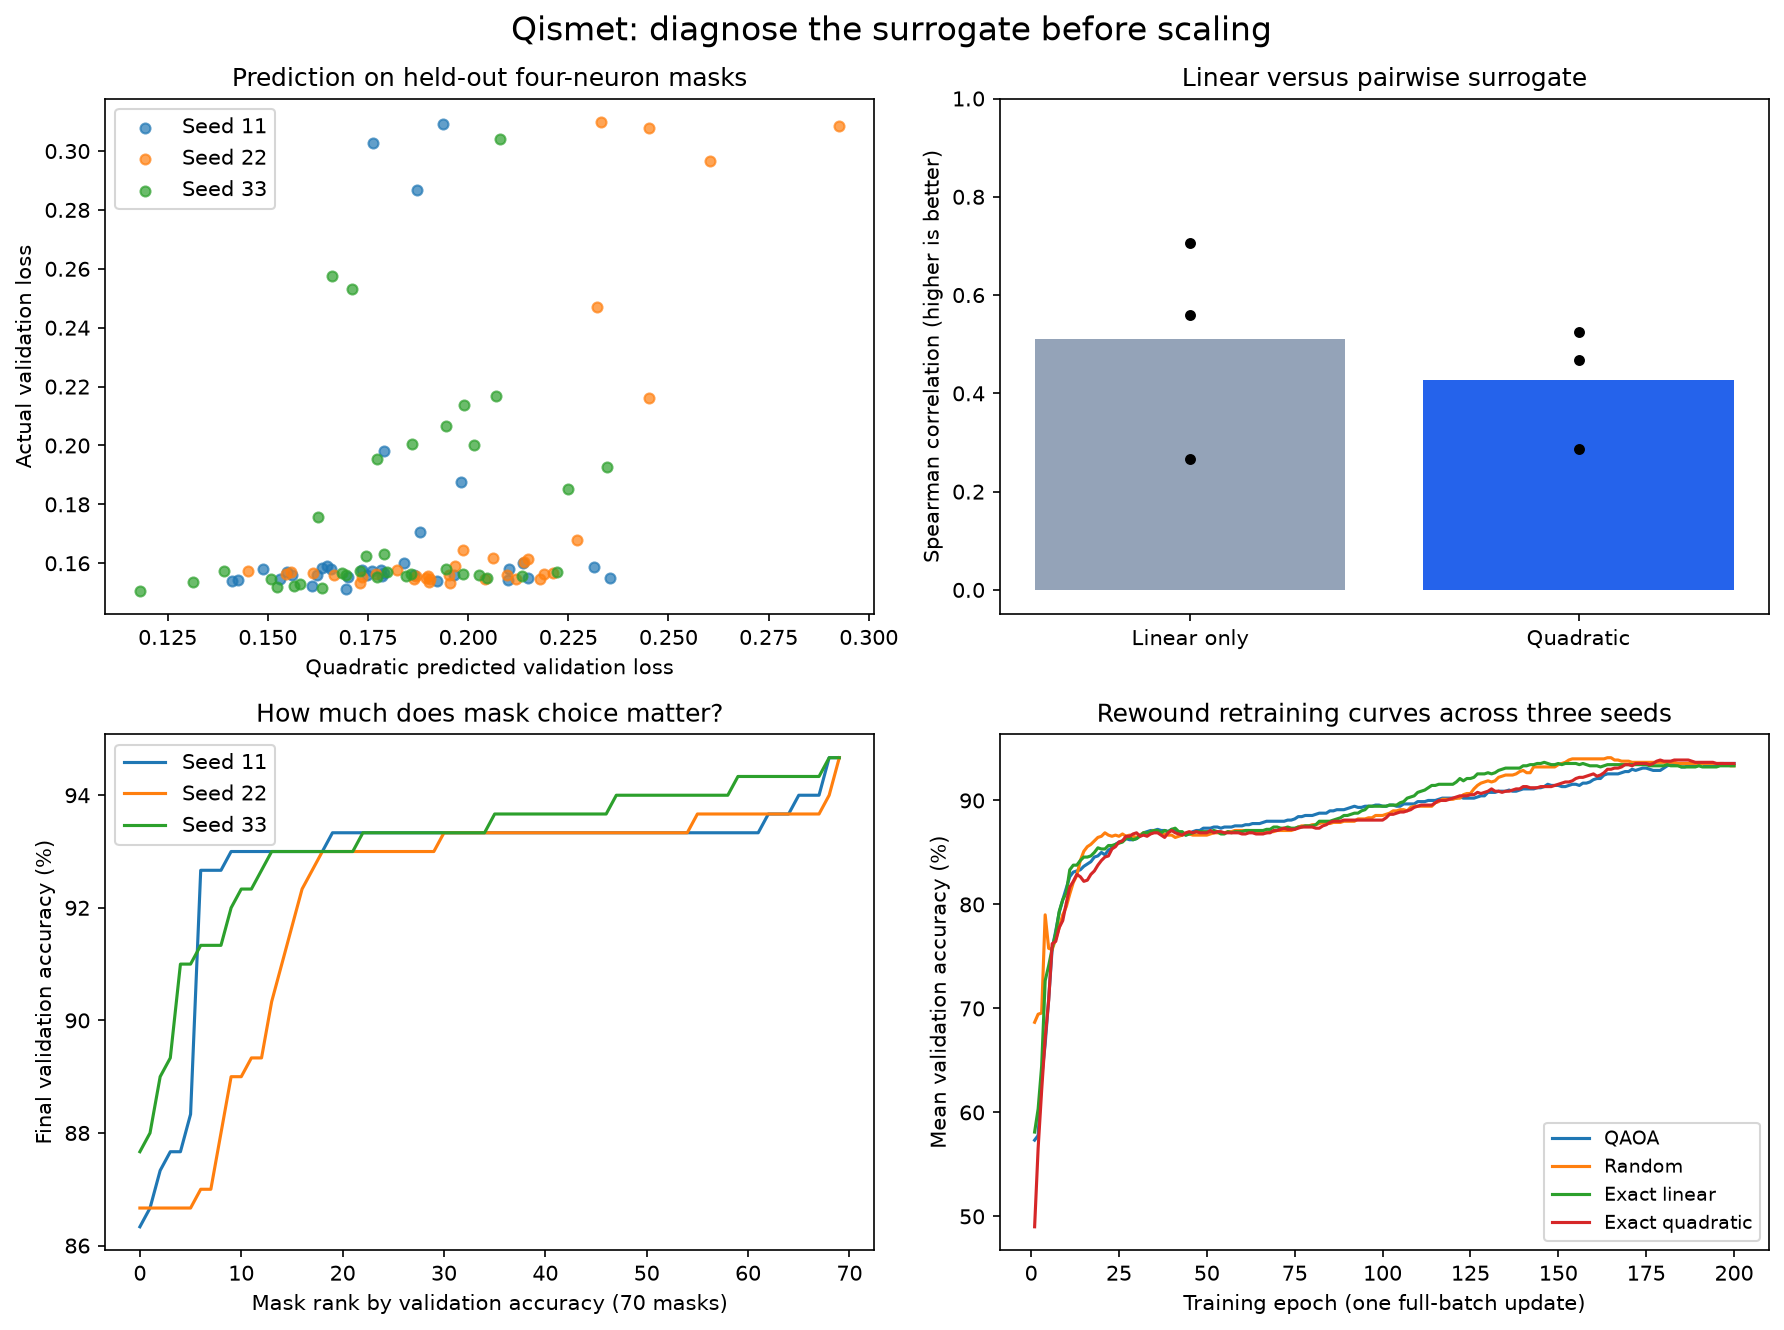

In [5]:
display(Image(filename=str(BASE/'qubo_audit.png')))

In [6]:
display(Markdown((BASE/'RESULTS.md').read_text(encoding='utf-8')))

# QUBO diagnostic: original Two Moons experiment

This is an **exploratory follow-up** on the original three initializations and mask audit split.
It reuses existing audit labels; it is not a fresh confirmatory test or a new dataset trial.
Test data was not evaluated or used for any audit decisions.

## Does QAOA solve the surrogate?

| seed | qaoa_mask | random_mask | exact_qubo_mask | qaoa_random_hamming | qaoa_equals_exact | qaoa_surrogate_gap |
| --- | --- | --- | --- | --- | --- | --- |
| 11 | 10111000 | 01010101 | 11101000 | 6 | False | 0.004643 |
| 22 | 10011001 | 01010101 | 10001011 | 4 | False | 0.009324 |
| 33 | 01010101 | 00101011 | 11010001 | 6 | False | 0.020972 |

QAOA's selected mask differs from the single random mask in every initialization, and does not
equal the exact surrogate optimum in any of the three. The gap is measured in unpenalized
predicted validation cross-entropy; all compared masks satisfy the same cardinality.

## Do pairwise terms improve prediction?

Both models use exactly the same original 128 fitting labels and five-fold CV with the same
alpha grid. The 35 held-out feasible masks per initialization are excluded from fitting and CV.
The original quadratic coefficients are reused unchanged. Positive cost/loss correlation is
desirable; negative cost/accuracy correlation is desirable.

| seed | model | n_audit | MAE | R2 | Spearman_cost_vs_loss | ridge_alpha | Spearman_cost_vs_accuracy |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 11 | Linear only | 35 | 0.0432 | -0.3978 | 0.2658 | 1.0 | -0.3385 |
| 11 | Quadratic | 35 | 0.032 | -0.2622 | 0.2874 | 0.1 | -0.3135 |
| 22 | Linear only | 35 | 0.0392 | 0.1991 | 0.5588 | 1.0 | -0.1768 |
| 22 | Quadratic | 35 | 0.0362 | 0.2997 | 0.5246 | 1.0 | -0.1642 |
| 33 | Linear only | 35 | 0.031 | -0.013 | 0.7059 | 1.0 | -0.5166 |
| 33 | Quadratic | 35 | 0.0287 | -0.1224 | 0.4678 | 0.0001 | -0.4565 |

Mean audit metrics:

| model | MAE | R2 | Spearman_cost_vs_loss | Spearman_cost_vs_accuracy |
| --- | --- | --- | --- | --- |
| Linear only | 0.0378 | -0.0706 | 0.5102 | -0.344 |
| Quadratic | 0.0323 | -0.0283 | 0.4266 | -0.3114 |

## Does selecting by the surrogate help?

All 70 feasible masks were retrained from saved initializations, with exactly the original
200 full-batch Adam steps and fresh optimizer. Final validation losses matched the saved
labels within 1e-7. Validation accuracy was measured at every epoch. The oracle below is a
retrospective validation-loss reference, not a deployable selector or test-set optimum.
Audit-only selection compares both surrogates on masks whose labels neither saw during fitting.

| candidate_pool | method | val_loss | val_accuracy | val_loss_regret |
| --- | --- | --- | --- | --- |
| all70 | Exact linear | 0.1547 | 0.93333 | 0.00344 |
| all70 | Exact quadratic | 0.15489 | 0.93556 | 0.00362 |
| all70 | QAOA | 0.15777 | 0.93556 | 0.0065 |
| all70 | Random | 0.1556 | 0.93333 | 0.00434 |
| all70 | Validation oracle (diagnostic) | 0.15126 | 0.93556 | 0.0 |
| audit35 | Audit-only linear | 0.15551 | 0.93111 | 0.00385 |
| audit35 | Audit-only oracle (diagnostic) | 0.15166 | 0.93667 | 0.0 |
| audit35 | Audit-only quadratic | 0.15394 | 0.93556 | 0.00228 |

## How much performance variation is available?

| seed | min_val_accuracy | max_val_accuracy | median_val_accuracy | fraction_within_1pp_best | min_val_loss | max_val_loss |
| --- | --- | --- | --- | --- | --- | --- |
| 11 | 0.86333 | 0.94667 | 0.93333 | 0.11429 | 0.15129 | 0.30902 |
| 22 | 0.86667 | 0.94667 | 0.93333 | 0.21429 | 0.15246 | 0.31192 |
| 33 | 0.87667 | 0.94667 | 0.935 | 0.5 | 0.15004 | 0.30398 |

The plot shows held-out cost/loss scatter, the pairwise ablation, the complete feasible-mask
performance spread, and selected-mask retraining curves. These are descriptions of three
initializations, not statistically established advantages. Pairwise features can improve fit
without reliably improving selection; read both tables together. A stronger dataset will not
automatically repair either surrogate error or QAOA optimization error.

Reproducibility: run `python run_audit.py` from this folder (or any working directory), with
the original sibling `results/` and `experiment_utils.py` available. It writes six CSVs and
`qubo_audit.png`. No original files are modified. Audit elapsed time: 42.8 seconds.
